The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


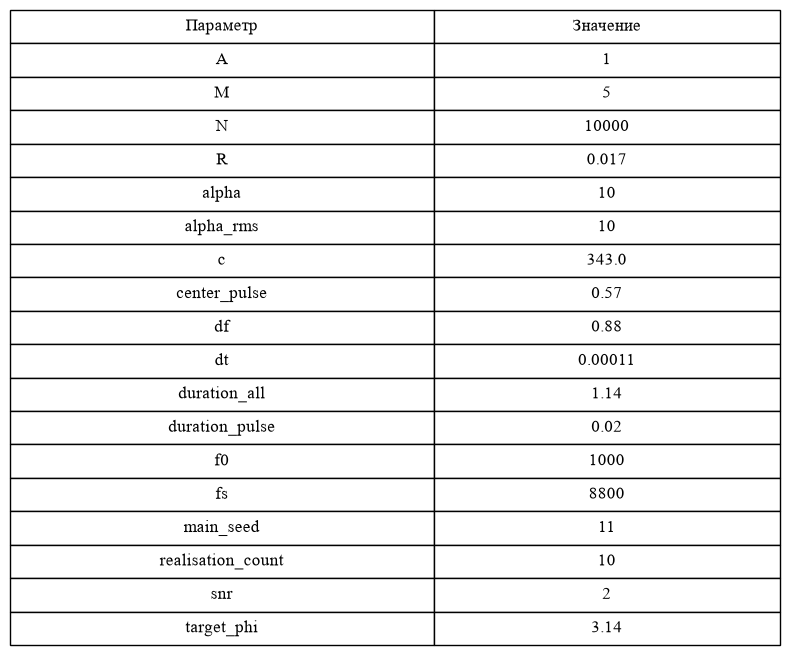

In [8]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.configs.config as cfg
import py_files.configs.comon as comon
import os
from py_files.plot_scrip import create_and_save_table, create_config_table
from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       calculate_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       calculate_stiring_matrix, 
                       get_est_phi,
                       calculate_capon_values,
                       calculate_fft, 
                       calculate_f_rms, 
                       filtering_spectrum, 
                       calculate_ifft,calculate_99, filering_signal)

config_parametrs = cfg.init_rng()
path = "images/draft"
os.makedirs(path,exist_ok=True)

create_config_table(config_parametrs)

In [9]:
def test_sinus_freq_rms():
    """Тест сранивает численное вычисление f rms для синусоиду 
    и центральную частоту """

    config_params = cfg.init_rng()
    sin_signal = get_sin_signal(config_params)
    freq_sin_pulse = calculate_fft(sin_signal, config_params["fs"])
    freq_rms = calculate_f_rms(freq_sin_pulse, config_params)


    return freq_rms, config_params["f0"]
a, b = test_sinus_freq_rms()
b/a

np.float64(0.9996983415921801)

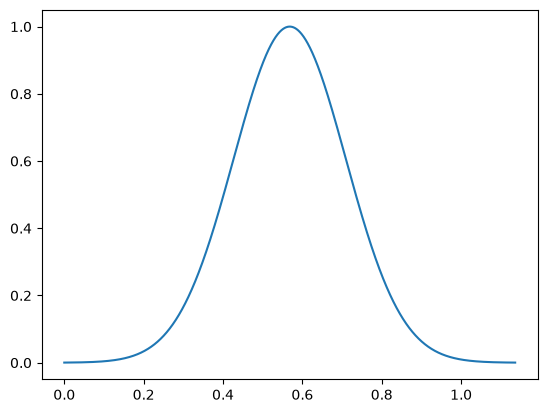

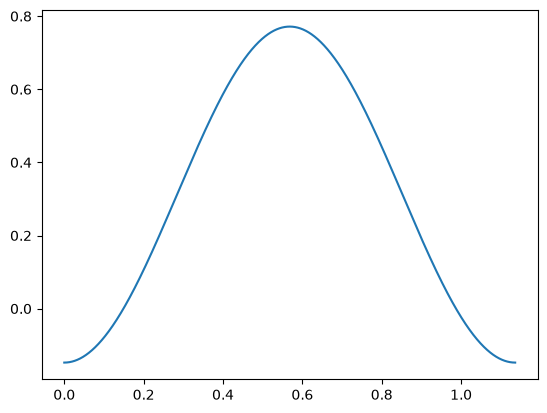

E = 0.2506628241113787
F99 = 1.7599999999999998
E_99 = 0.23058594403953447
91.99048357369367


In [10]:
sigma = 0.2
t0 = comon.DURATION_ALL / 2
gauss_pulse = np.exp(-((cfg.TIME_VECTOR - t0)/ sigma)**2)
spectrum = calculate_fft(gauss_pulse, comon.FS)
E_gaus = calculate_energy(gauss_pulse,cfg.TIME_VECTOR)
filt_rect = filering_signal(gauss_pulse, 100, comon.FS)
f99 = calculate_99(cfg.FREQ_VECTOR, spectrum)

filt_rect = filering_signal(gauss_pulse, f99, comon.FS)

E_rect_filt = calculate_energy(filt_rect,cfg.TIME_VECTOR)
plt.plot(cfg.TIME_VECTOR, gauss_pulse)
plt.show()
plt.plot(cfg.TIME_VECTOR, filt_rect)
plt.show()

print(f"E = {E_gaus}")
print(f"F99 = {f99}")
print(f"E_99 = {E_rect_filt}")
print((E_rect_filt/E_gaus)*100)